# B-8802B · o modelo, a falha e o ciclo de retreino

1. **A falha real de 2022** — o que o modelo mostra.
2. **Uma falha simulada em 2026** — o mesmo teste no regime atual.
3. **O ciclo de retreino** — a bomba volta do reparo em 2025 operando de outro jeito: quando o monitor percebe, quando
   cada modelo novo (1, 3, 6 e 12 meses) entra e quantos avisos cada um dá.
4. **Depois do modelo de 12 meses** — como ele se comporta no resto dos dados.
5. **Grade de retreino × AutoML** — por que o retreino não precisa de busca ampla de hiperparâmetros.

Os modelos de 1, 3, 6 e 12 meses foram treinados pelo próprio pipeline de retreino (`retrain_pipeline.py`), como se
estivesse em produção, e cada um passou na bateria de testes antes de "entrar".

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from transpetro_modelos.drift import battery, monitor as mon
B = battery.BATTERY["B-8802B-2025"]; si = battery.si
CSV = Path(B["data_new"])
raw = si.carregar_dados(CSV)
raw22 = si.carregar_dados(next(Path(B["cross_era"]["csv"]).rglob(B["cross_era"]["csv_glob"])))
FALHA, RAMPA22 = pd.Timestamp(B["cross_era"]["failure"]), pd.Timestamp(B["cross_era"]["ramp_start"])
PRODUCAO = Path(B["bundle"])
R = RAIZ / "results/replay_pipeline"
VERMELHO, SERIE, TEXTO = "#e5484d", "#6f9fd1", "#52514e"
plt.rcParams.update({"font.size": 11})

def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

def alertas(bundle, df, ini, fim):
    """Alerta que chega à operação (regra de produção), com 2 dias de dado antes para a persistência."""
    torch.manual_seed(0)
    r = battery.score(bundle, df.loc[pd.Timestamp(ini) - pd.Timedelta(days=2):fim])
    return r.loc[ini:fim, "is_anomaly"].astype(bool)

def operando(df):
    """Vibração LA só com a bomba operando (as paradas viram buraco no gráfico)."""
    return df["Vibração Bomba LA"].where(df["Pressão Descarga"] > 35)

def episodios(f):
    x = f[f]
    if x.empty: return []
    g = x.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()
    return [(e.index[0], e.index[-1]) for _, e in x.groupby(g)]

## 1. A falha real de 2022

Trinca nas lâminas do acoplamento em **06/07/2022 às 10:00**. Vibração do mancal LA nos 10 dias antes; os pontos
vermelhos são os instantes em **alerta** do modelo em produção (o que chega à operação).

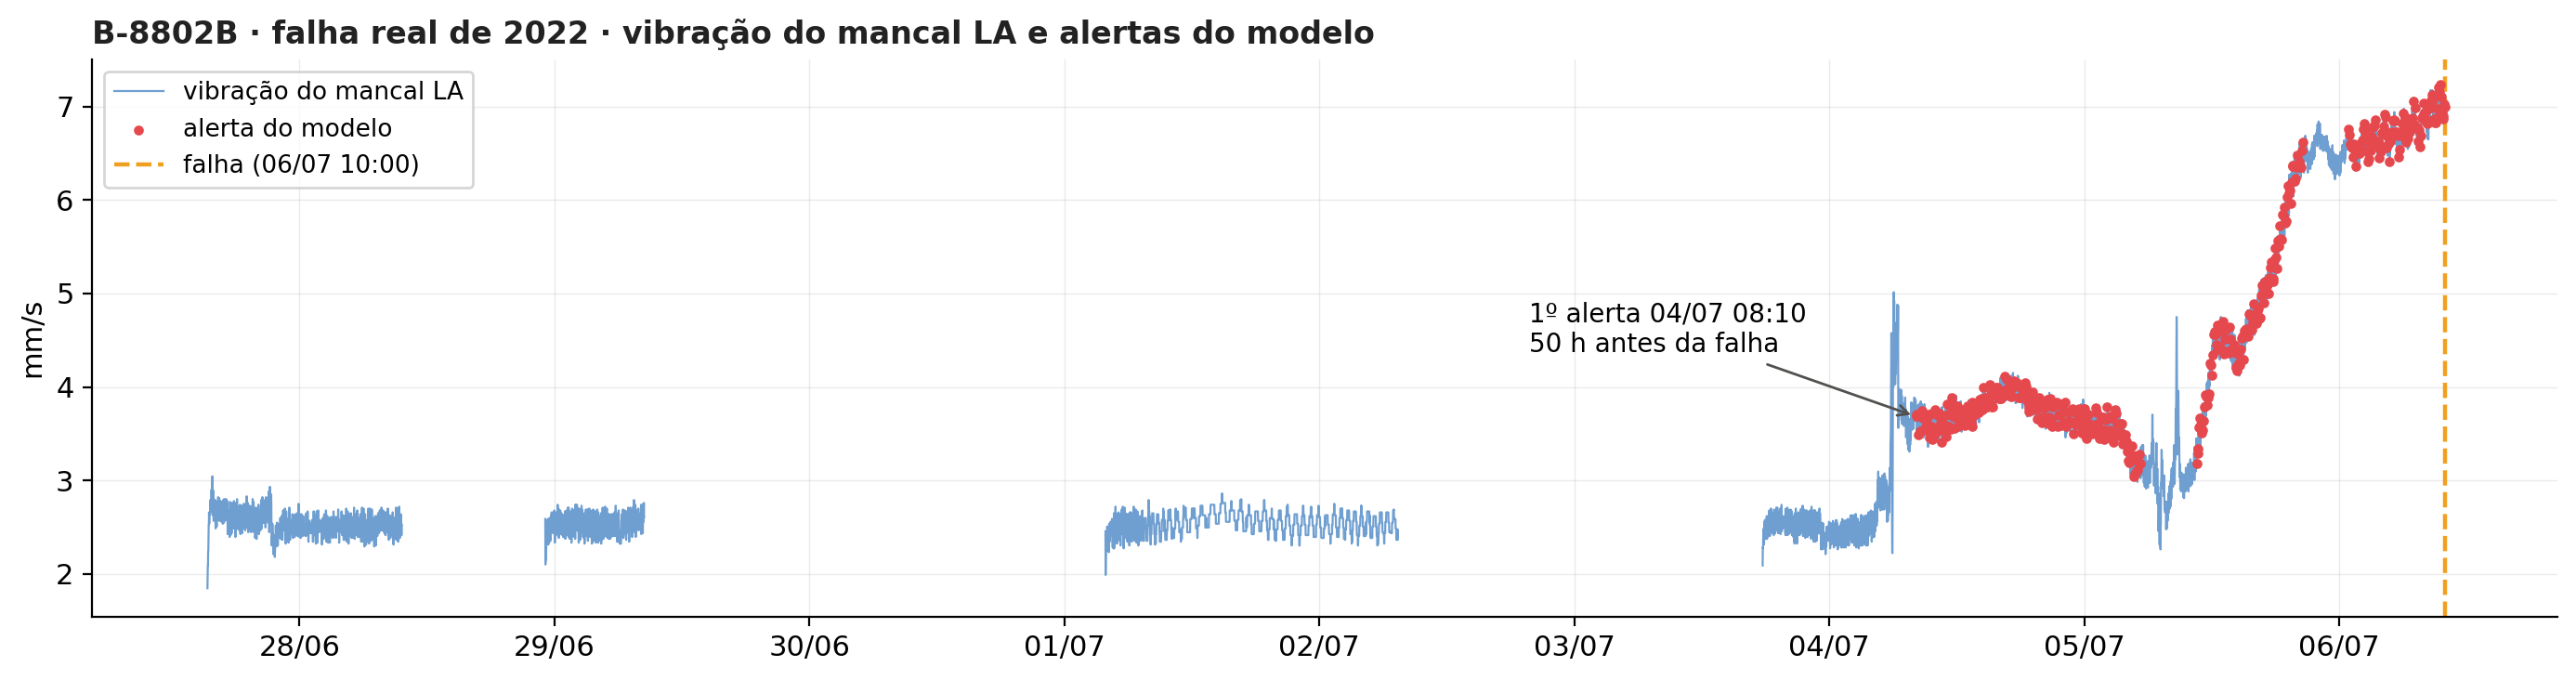

In [2]:
ini, fim = "2022-06-27", FALHA
a = alertas(PRODUCAO, raw22, ini, fim)
v = operando(raw22.loc[ini:fim])
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(v.index, v.values, color=SERIE, lw=0.8, label="vibração do mancal LA")
pts = v.reindex(a.index)[a]
ax.scatter(pts.index, pts.values, color=VERMELHO, s=8, zorder=3, label="alerta do modelo")
ax.axvline(FALHA, color="#f0a020", ls="--", lw=1.6, label="falha (06/07 10:00)")
t1 = a[a].index.min()
ax.annotate(f"1º alerta {t1:%d/%m %H:%M}\n{(FALHA - t1).total_seconds() / 3600:.0f} h antes da falha", (t1, pts.iloc[0]),
            xytext=(-150, 25), textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->", color=TEXTO))
ax.set_ylabel("mm/s"); ax.legend(fontsize=9.5, loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
estilo(ax, "B-8802B · falha real de 2022 · vibração do mancal LA e alertas do modelo")
fig.tight_layout()

**Leitura:** até 04/07 a vibração está normal (~2,5 mm/s) e o modelo fica quieto. Em 04/07 ela salta para ~3,8 e
o modelo alerta na hora — **~2 dias antes da falha** — e segue em alerta até a quebra. A antecedência é a que o dado
permite: antes de 04/07 os sensores não mostram nada.

## 2. Uma falha simulada em 2026

Não houve falha em 2026. Para testar o modelo no regime atual, somamos ao dado real a **assinatura medida da falha de
2022** (vibrações e temperatura subindo, pressão de descarga caindo), numa rampa de 48 h a partir de 10/06/2026,
seguida de 24 h no nível máximo.

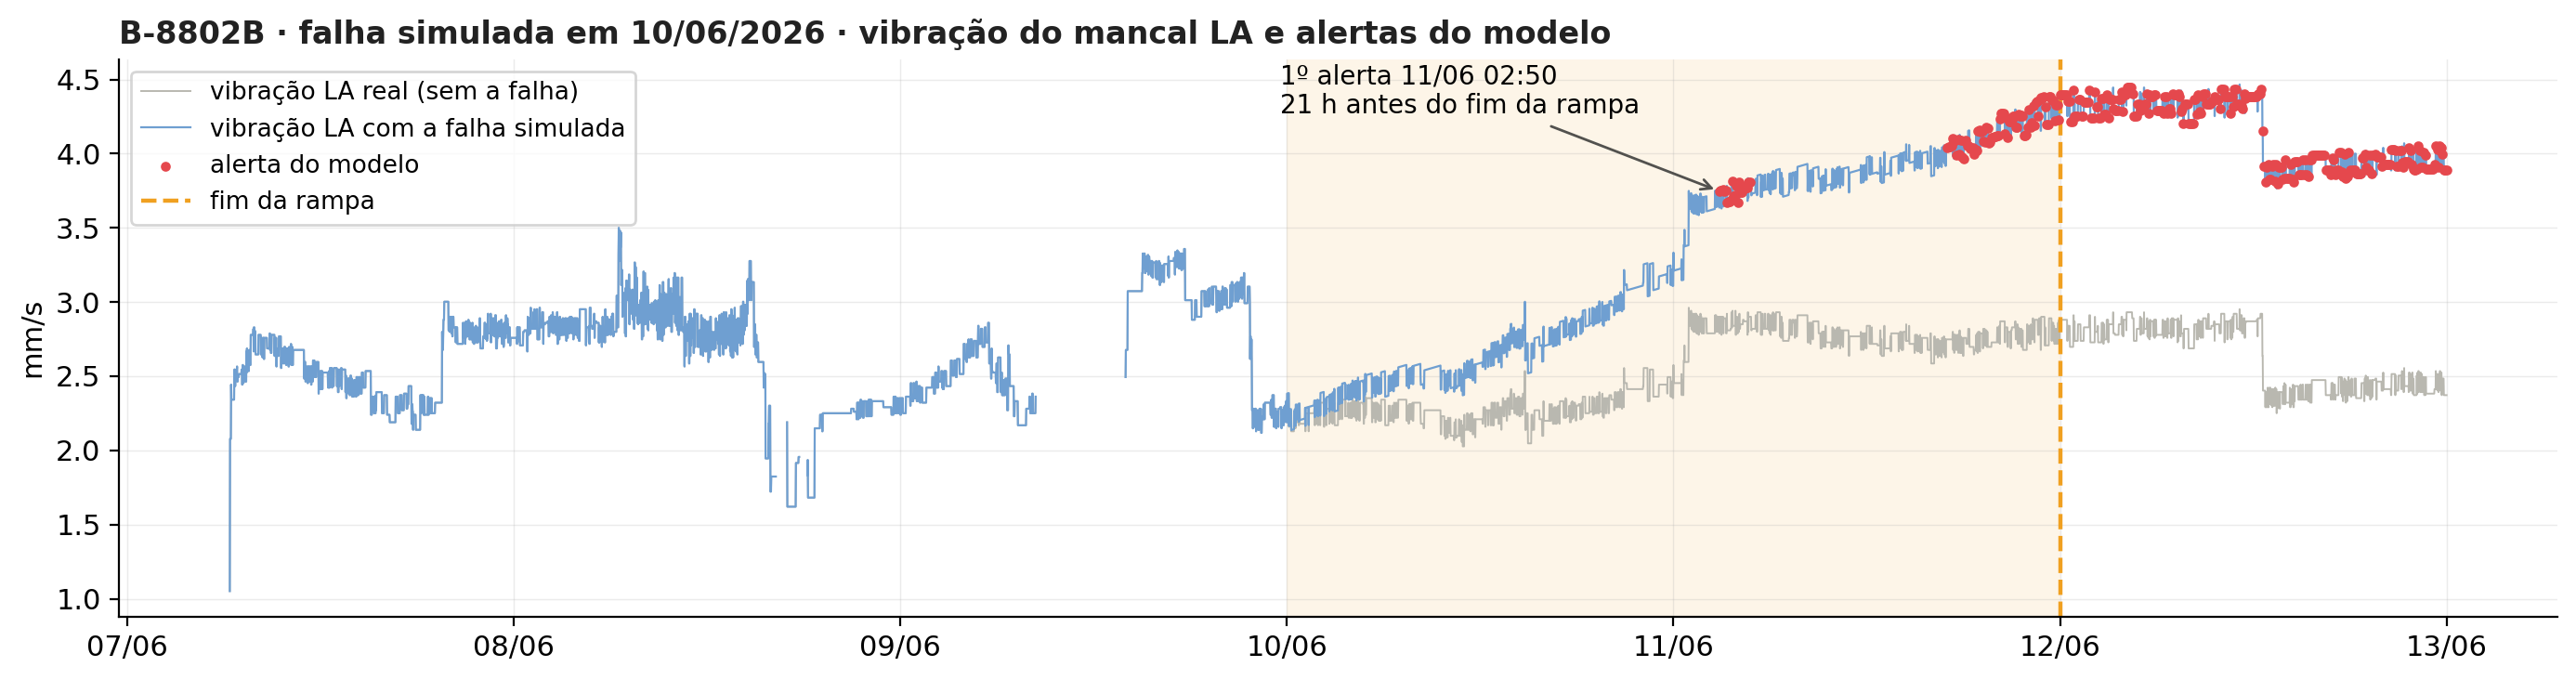

In [3]:
t0 = pd.Timestamp("2026-06-10"); tf = t0 + pd.Timedelta(hours=48); fim = tf + pd.Timedelta(hours=24)
sy = B["synthetic"]
inj = battery.inject(raw.loc[t0 - pd.Timedelta(days=5): fim], sy["signature"], t0, 48, 24, 1.0)
ini = t0 - pd.Timedelta(days=3)
a = alertas(PRODUCAO, inj, ini, fim)
fig, ax = plt.subplots(figsize=(14, 3.8))
v0, v = operando(raw.loc[ini:fim]), operando(inj.loc[ini:fim])
ax.plot(v0.index, v0.values, color="#b9b8b0", lw=0.7, label="vibração LA real (sem a falha)")
ax.plot(v.index, v.values, color=SERIE, lw=0.8, label="vibração LA com a falha simulada")
pts = v.reindex(a.index)[a]
ax.scatter(pts.index, pts.values, color=VERMELHO, s=8, zorder=3, label="alerta do modelo")
ax.axvspan(t0, tf, color="#f0a020", alpha=0.10, lw=0); ax.axvline(tf, color="#f0a020", ls="--", lw=1.6, label="fim da rampa")
if a.any():
    t1 = a[a].index.min()
    ax.annotate(f"1º alerta {t1:%d/%m %H:%M}\n{(tf - t1).total_seconds() / 3600:.0f} h antes do fim da rampa",
                (t1, v.asof(t1)), xytext=(-170, 30), textcoords="offset points", fontsize=10,
                arrowprops=dict(arrowstyle="->", color=TEXTO))
ax.set_ylabel("mm/s"); ax.legend(fontsize=9.5, loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
estilo(ax, "B-8802B · falha simulada em 10/06/2026 · vibração do mancal LA e alertas do modelo")
fig.tight_layout()

**Leitura:** o modelo alerta durante a rampa, ~20 h antes de ela chegar ao máximo. É o mesmo comportamento da
falha real, agora no regime de 2026.

## 3. O ciclo de retreino (2025)

A bomba foi reparada depois da falha de 2022 e voltou a operar em 2025 de outro jeito (vibração mais alta e mais
variável). O que acontece, passo a passo:

| quando | o que acontece |
|---|---|
| jan/2025 | o modelo de 2022 (treinado com maio–junho/2022) ainda está em produção |
| **09/01/2025** | o **monitor** percebe a mudança (o KS diário dispara pela vibração LA) e fica amarelo |
| logo depois | a operação confirma: é o normal novo depois do reparo, sem falha. Os alertas do modelo velho passam a valer "com ressalva" |
| **06/02/2025** | com **1 mês** de dado novo, o pipeline treina o modelo provisório de 1 mês → bateria → entra |
| **06/04/2025** | modelo de **3 meses** (mesmo início, mais dado) → bateria → entra |
| **06/07/2025** | modelo de **6 meses** → bateria → entra |
| **06/01/2026** | modelo de **12 meses** → bateria → entra e fica **fixo** até a próxima mudança confirmada |

Nenhum passo é automático sem a confirmação da operação: o monitor também reage a uma degradação real, e retreinar
nela colocaria a falha dentro do "normal".

In [4]:
ETAPAS = [("2022", R / "modelo_2022_regras_novas", "2025-01-01", "2025-02-06", "#8a897f"),
          ("1 mês", next((R / "m01").glob("model_*")), "2025-02-06", "2025-04-06", "#9ec5f0"),
          ("3 meses", next((R / "m03").glob("model_*")), "2025-04-06", "2025-07-06", "#5b9be0"),
          ("6 meses", next((R / "m06").glob("model_*")), "2025-07-06", "2026-01-06", "#2a6fc4"),
          ("12 meses (fixo)", next((R / "m12").glob("model_*")), "2026-01-06", "2026-08-11", "#1b3f7a")]
resumo = pd.read_csv(R / "resumo.csv").set_index("etapa")
al, avisos, linhas = [], [], []
for nome, b, ini, fim, cor in ETAPAS:
    a = alertas(b, raw, ini, fim); al.append(a)
    m6 = [(t, "M6") for t, s in mon.ks_daily_fires(CSV, b) if pd.Timestamp(ini) <= t < pd.Timestamp(fim)]
    m8 = [(pd.Timestamp(t), "M8") for t, s in mon.residual_fires(CSV, b) if pd.Timestamp(ini) <= pd.Timestamp(t) < pd.Timestamp(fim)] \
         if (b / "residual_ref.json").exists() else []
    avisos += [(t, k, cor) for t, k in m6 + m8]
    k = {"1 mês": 1, "3 meses": 3, "6 meses": 6, "12 meses (fixo)": 12}.get(nome)
    r = resumo.loc[k] if k else None
    linhas.append({"modelo": nome,
                   "treinado com": "mai–jun/2022" if k is None else f"06/01/25 → {pd.Timestamp(r.treino_fim):%d/%m/%y}",
                   "em operação": f"{pd.Timestamp(ini):%d/%m/%y} → {min(pd.Timestamp(fim), raw.index.max()):%d/%m/%y}",
                   "alertas (episódios)": len(episodios(a)),
                   "avisos do monitor (dias)": len({t.date() for t, *_ in m6 + m8}),
                   "bateria: falha 2022 (dias antes)": None if k is None else round(r.falha_2022_dias, 1),
                   "bateria: falha simulada (h antes)": None if k is None else round(r.sintetica_h)})
alerta = pd.concat(al).sort_index(); alerta = alerta[~alerta.index.duplicated()]
tab = pd.DataFrame(linhas).set_index("modelo"); tab

,treinado com,em operação,alertas (episódios),avisos do monitor (dias),bateria: falha 2022 (dias antes),bateria: falha simulada (h antes)
modelo,,,,,,
2022,mai–jun/2022,01/01/25 → 06/02/25,14,1,NaN,NaN
1 mês,06/01/25 → 06/02/25,06/02/25 → 06/04/25,0,3,2.1,15.0
3 meses,06/01/25 → 06/04/25,06/04/25 → 06/07/25,1,4,1.9,16.0
6 meses,06/01/25 → 06/07/25,06/07/25 → 06/01/26,0,6,2.1,10.0
12 meses (fixo),06/01/25 → 06/01/26,06/01/26 → 10/08/26,2,27,2.1,16.0


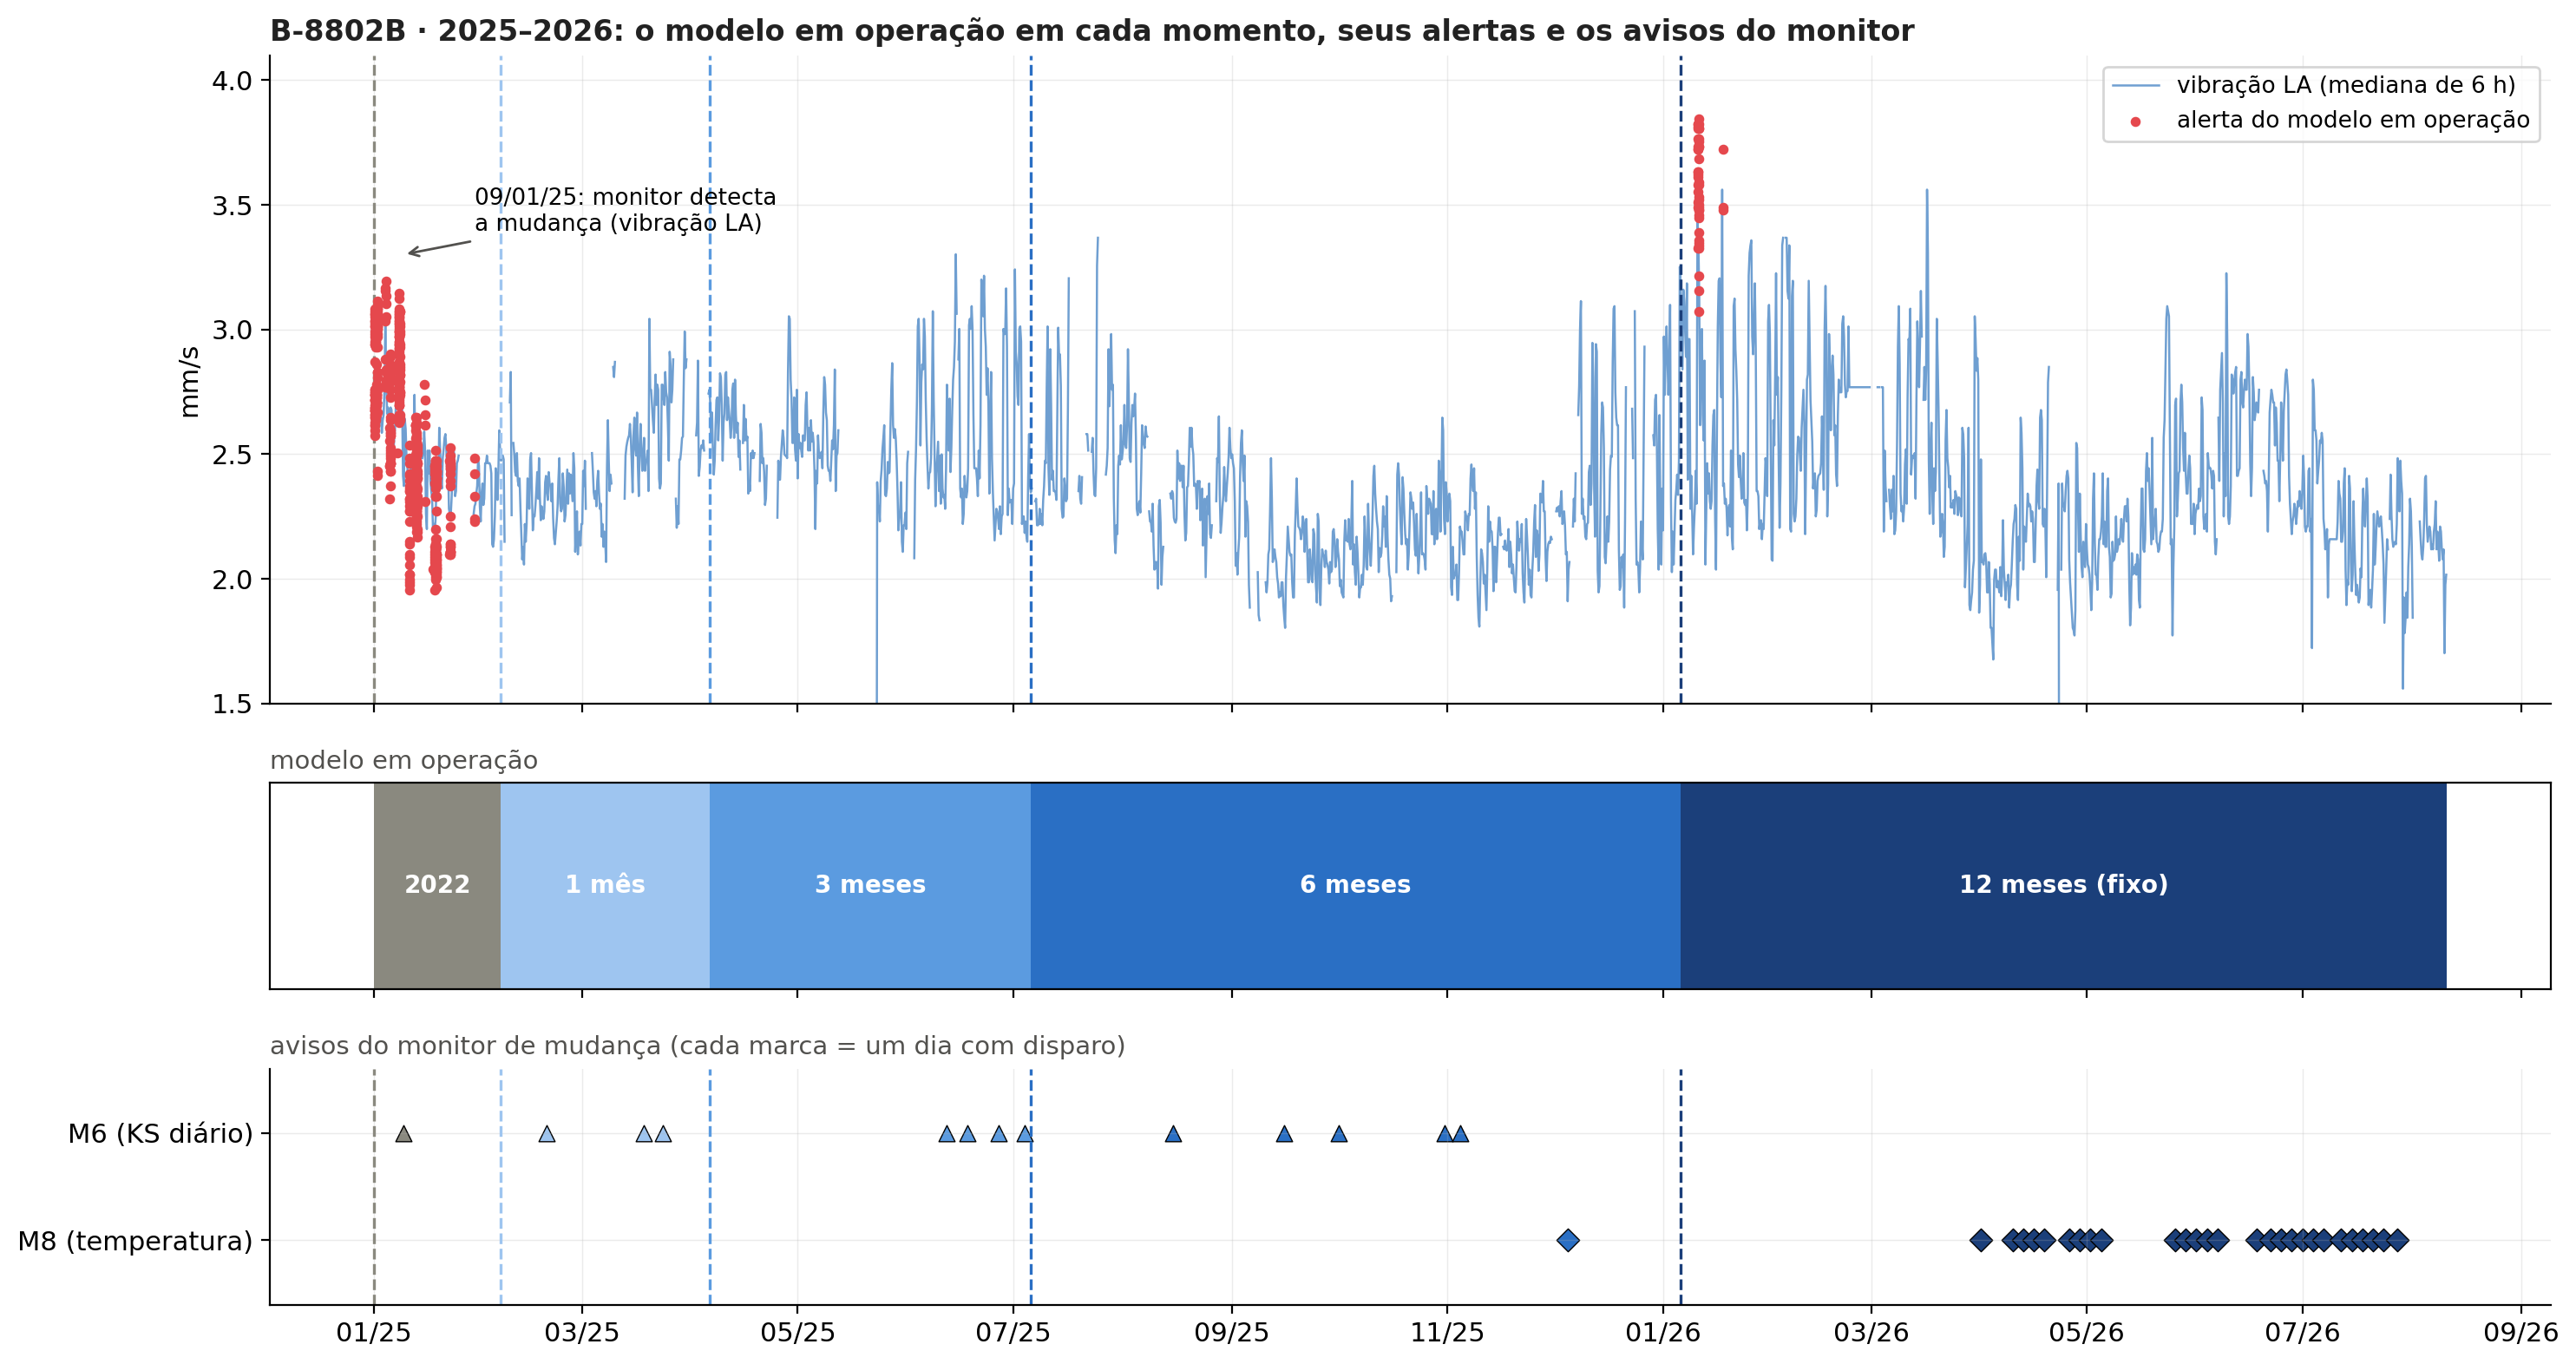

In [5]:
ini, fim = "2025-01-01", "2026-08-11"
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 0.7, 0.8]})
v = operando(raw.loc[ini:fim])
vm = v.resample("6h").median()
a1.plot(vm.index, vm.values, color=SERIE, lw=0.9, label="vibração LA (mediana de 6 h)")
pts = v.reindex(alerta.index)[alerta]
a1.scatter(pts.index, pts.values, color=VERMELHO, s=10, zorder=3, label="alerta do modelo em operação")
a1.set_ylabel("mm/s"); a1.set_ylim(1.5, 4.1); a1.legend(fontsize=9.5, loc="upper right")
estilo(a1, "B-8802B · 2025–2026: o modelo em operação em cada momento, seus alertas e os avisos do monitor")
for nome, b, i, f, cor in ETAPAS:
    i, f = pd.Timestamp(i), min(pd.Timestamp(f), raw.index.max())
    a2.axvspan(i, f, color=cor, lw=0)
    a2.text(i + (f - i) / 2, 0.5, nome, ha="center", va="center", fontsize=10, color="white", fontweight="bold")
    for ax in (a1, a3):
        ax.axvline(i, color=cor, lw=1.2, ls="--")
a2.set_yticks([]); a2.set_ylim(0, 1); a2.set_title("modelo em operação", loc="left", fontsize=10.5, color=TEXTO)
for t, k, cor in avisos:
    a3.scatter([t], [1 if k == "M6" else 0], marker="^" if k == "M6" else "D", s=45, color=cor, edgecolor="black", lw=0.5)
a3.set_yticks([0, 1], ["M8 (temperatura)", "M6 (KS diário)"]); a3.set_ylim(-0.6, 1.6)
a3.set_title("avisos do monitor de mudança (cada marca = um dia com disparo)", loc="left", fontsize=10.5, color=TEXTO)
a3.spines[["top", "right"]].set_visible(False); a3.grid(alpha=0.25, lw=0.5)
a1.annotate("09/01/25: monitor detecta\na mudança (vibração LA)", (pd.Timestamp("2025-01-09"), 3.3), xytext=(30, 10),
            textcoords="offset points", fontsize=9.5, arrowprops=dict(arrowstyle="->", color=TEXTO))
a3.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout()

**Leitura:**
- **O monitor percebe a mudança em 09/01/2025**, 8 dias depois do início do dado novo. Daí até o modelo de 1 mês
  entrar (06/02) o modelo de 2022 continua rodando, com os alertas "com ressalva".
- **Cada modelo novo passou na bateria** antes de entrar (falha de 2022 ~2 dias antes; falha simulada detectada).
- **Alertas da operação** (pontos vermelhos):
  - o **modelo de 2022** alerta bastante em janeiro (14 episódios): ele não conhece o normal novo. É por isso que os
    alertas dele valem "com ressalva" até o modelo de 1 mês entrar;
  - depois do retreino, quase nada: o modelo de 3 meses tem 1 episódio, no fim de maio, quando o **sensor de vibração
    ficou zerado** (falha de instrumento, que o monitor também marca como dado congelado), não da bomba;
  - o modelo de 12 meses alerta só nos dois episódios de vibração de janeiro/2026 (próxima seção).
- **Avisos do monitor durante 2025** (marcas coloridas): são esperados. Um modelo de 1, 3 ou 6 meses ainda não viu o
  ano inteiro, então o monitor estranha a estação. Nessa fase eles **não pedem retreino novo**: o calendário de 1, 3,
  6 e 12 meses já está andando. Eles só voltam a contar depois do modelo de 12 meses.

## 4. Depois do modelo de 12 meses (2026)

O modelo de 12 meses fica fixo. Como ele se comporta no resto dos dados, e o que o monitor diz:

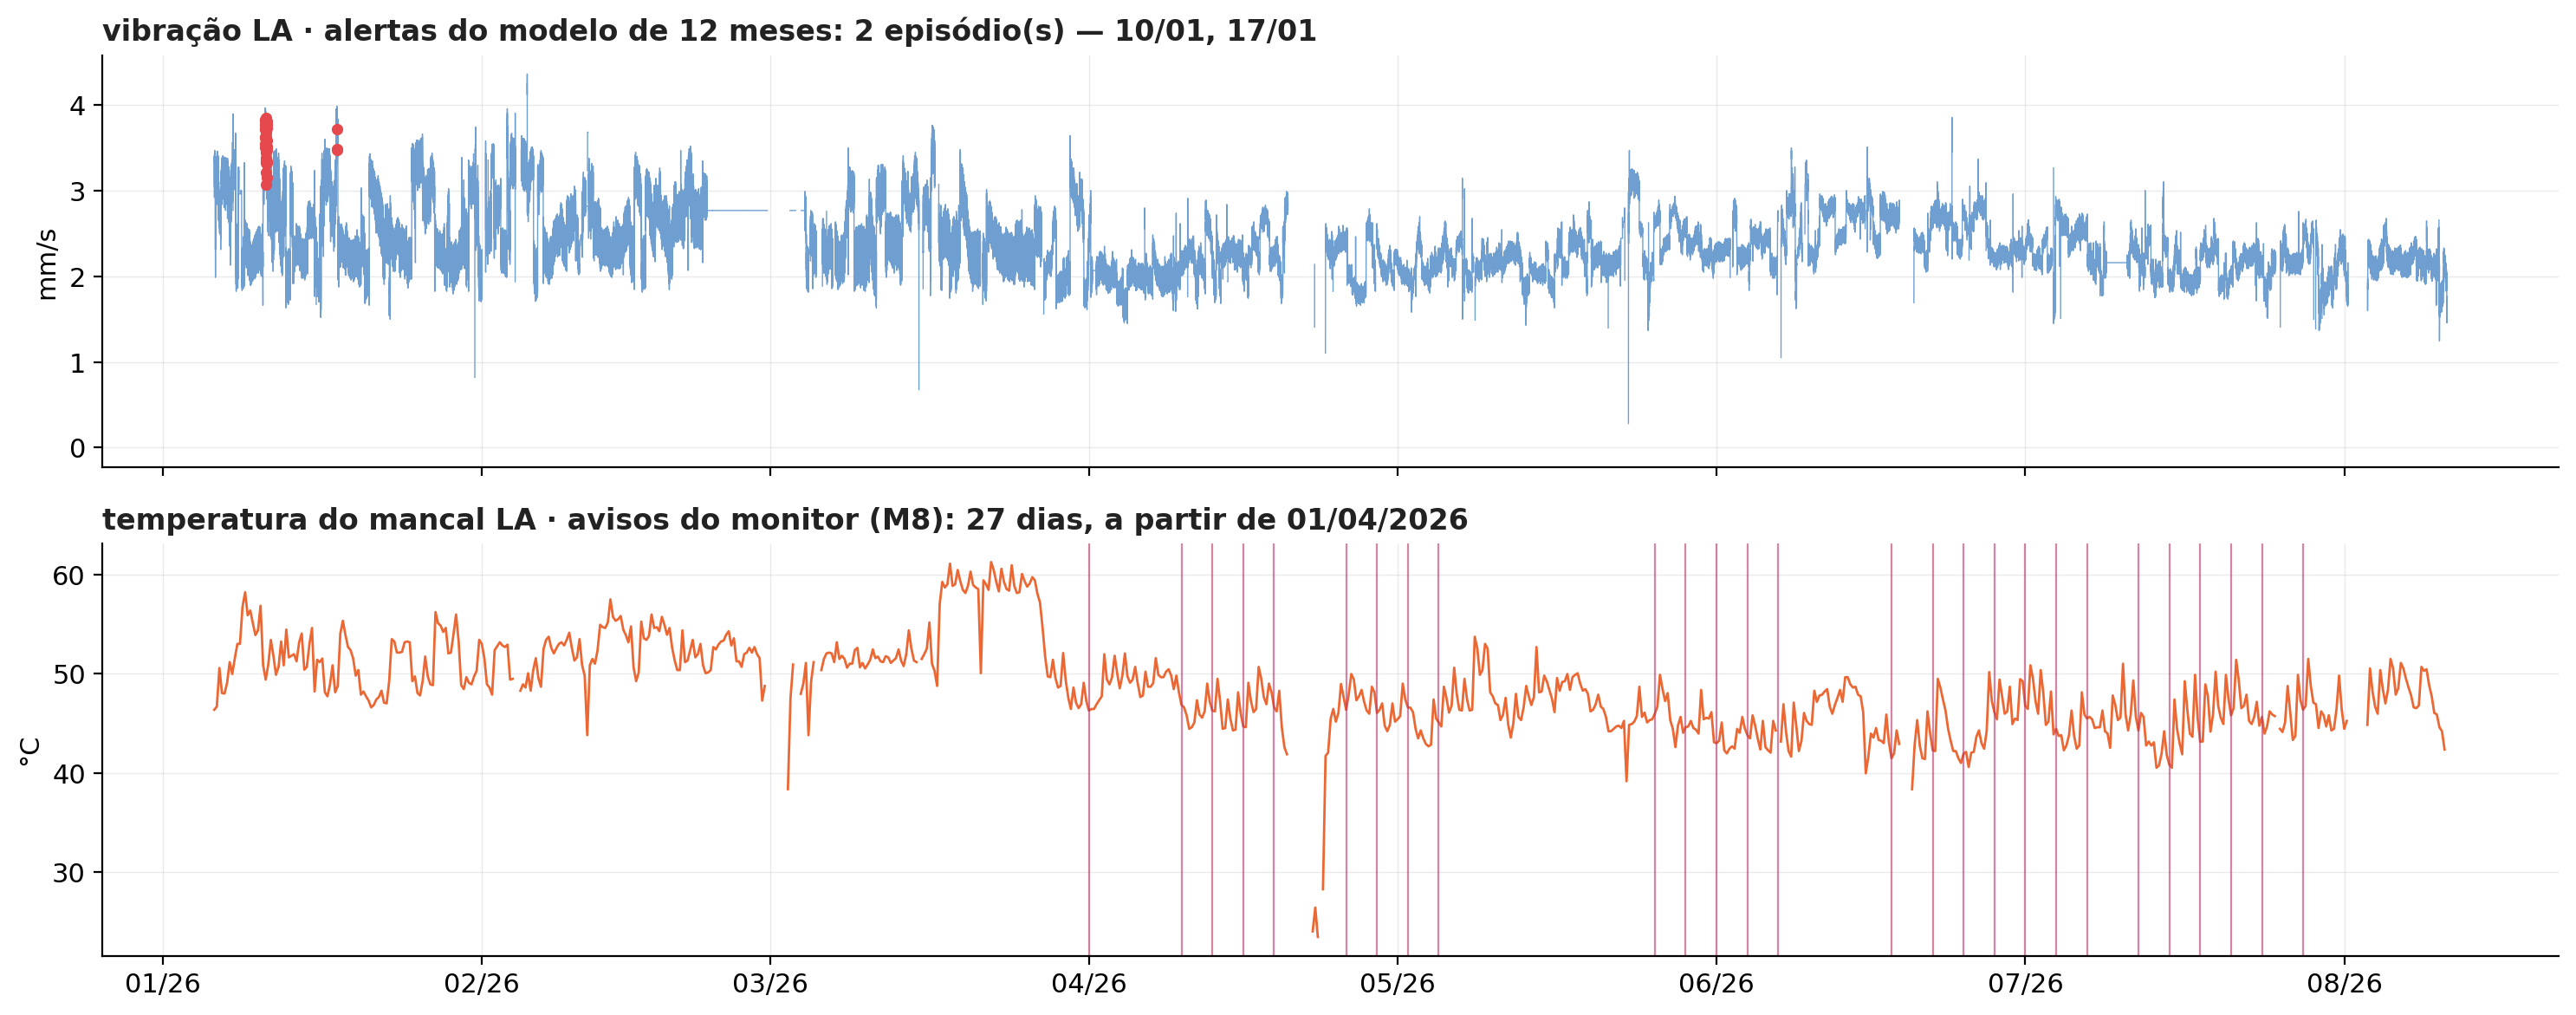

In [6]:
nome, b, ini, fim, cor = ETAPAS[-1]
w = raw.loc[ini:fim]
a = alerta.loc[ini:fim]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
v = operando(w)
a1.plot(v.index, v.values, color=SERIE, lw=0.5)
pts = v.reindex(a.index)[a]; a1.scatter(pts.index, pts.values, color=VERMELHO, s=14, zorder=3)
eps = episodios(a)
estilo(a1, f"vibração LA · alertas do modelo de 12 meses: {len(eps)} episódio(s) — " + ", ".join(f"{i:%d/%m}" for i, _ in eps))
a1.set_ylabel("mm/s")
t = w["Temperatura Bomba LA"].where(w["Pressão Descarga"] > 35).resample("6h").median()
a2.plot(t.index, t.values, color="#eb6834", lw=1)
m8 = sorted({tt for tt, k, _ in avisos if k == "M8" and tt >= pd.Timestamp(ini)})
for tt in m8: a2.axvline(tt, color="#b8336a", lw=0.8, alpha=0.6)
estilo(a2, f"temperatura do mancal LA · avisos do monitor (M8): {len(m8)} dias, a partir de {m8[0]:%d/%m/%Y}" if m8 else "temperatura do mancal LA")
a2.set_ylabel("°C"); a2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout()

**Leitura:**
- **O modelo alerta só em janeiro/2026**: 10/01 e 17/01, os dois episódios de vibração alta acima do normal de 2025
  (17/01 é tratado como real; 10–12/01 está em aberto com a operação). De fevereiro a agosto, nenhum alerta.
- **O monitor fica amarelo a partir de 01/04/2026** pelo M8: depois de uma parada no fim de março, a temperatura do
  mancal LA ficou ~6 °C abaixo do esperado e não voltou. É o momento em que o sistema **pediria a revisão**: a
  operação precisa dizer o que foi feito nas paradas de 17/03 e 27/03/2026.
- **Precisa retreinar?** Pelo que os dados mostram, ainda não: o modelo continua sem alertas falsos e detecta a falha
  simulada em junho/julho. Se a operação confirmar um normal novo, o ciclo recomeça (1, 3, 6, 12 meses); se não,
  mantém o modelo atual e acompanha.

## 5. Grade de retreino × AutoML

O modelo de produção (treinado com 2025) foi escolhido por um **AutoML** no ClearML — uma busca ampla de arquitetura e
hiperparâmetros. O modelo de 12 meses do ciclo acima saiu da **grade do retreino**: a mesma arquitetura, 4 configurações
× 3 sementes, escolha pela validação e aprovação pela bateria. Os dois, nos mesmos testes:

In [7]:
def bateria(b):
    a26 = alertas(b, raw, "2026-01-06", "2026-08-11")
    a22 = alertas(b, raw22, "2022-06-27", FALHA)
    t22 = a22[a22].index.min()
    lin = {"episódios de alerta em 2026": len(episodios(a26)),
           "falha 2022 (h antes)": round((FALHA - t22).total_seconds() / 3600) if t22 is not None else None}
    for d in ["2026-01-25", "2026-06-10", "2026-07-15"]:
        t0 = pd.Timestamp(d); tf = t0 + pd.Timedelta(hours=48); fim = tf + pd.Timedelta(hours=24)
        inj = battery.inject(raw.loc[t0 - pd.Timedelta(days=5): fim], B["synthetic"]["signature"], t0, 48, 24, 1.0)
        x = alertas(b, inj, t0, fim); t1 = x[x].index.min() if x.any() else None
        lin[f"simulada {t0:%d/%m} (h antes)"] = round((tf - t1).total_seconds() / 3600) if t1 is not None else "não detecta"
    return lin
comp = pd.DataFrame({"AutoML (modelo de produção)": bateria(PRODUCAO),
                     "grade do retreino (12 meses)": bateria(ETAPAS[-1][1])}).T
comp["tempo para obter"] = ["59 h no ClearML (busca ampla)", "~5 min (12 candidatos + bateria)"]
comp

,episódios de alerta em 2026,falha 2022 (h antes),simulada 25/01 (h antes),simulada 10/06 (h antes),simulada 15/07 (h antes),tempo para obter
AutoML (modelo de produção),1,50,28,21,7,59 h no ClearML (busca ampla)
grade do retreino (12 meses),2,50,31,23,10,~5 min (12 candidatos + bateria)


**Leitura:** os dois modelos se comportam praticamente igual: a mesma antecedência na falha de 2022 (50 h), a mesma
na falha simulada (a grade até um pouco mais cedo) e, em 2026, a grade alerta em 10/01 e 17/01 e o AutoML só em
17/01 — os dois só em janeiro. A grade leva minutos em vez de dias e é reproduzível. A arquitetura já foi escolhida pelo
AutoML uma vez; num retreino o equipamento e os sensores são os mesmos, então a busca ampla não traz ganho. **O AutoML
fica como reserva:** só roda se nenhum dos 12 candidatos da grade passar na bateria, se os sensores mudarem ou se for
um equipamento novo.

## Onde está documentado

- `deploy_v2/Transpetro/INTEGRACAO.md` — visão geral para a engenharia: inferência, monitor, retreino, requisitos
  (só CPU, ~1 GB de RAM, ~10 min), teste de aceitação e o que a integração recebe.
- `deploy_v2/Transpetro/MONITORAMENTO.md` — o monitor semanal (como rodar e ler) e o fluxo de retreino com quem faz cada passo.
- `docs/politica_retreino.md` — a política (quando retreinar, 1/3/6/12 meses, sombra, troca).